STEP 1: Create a 2-qubit circuit
Initial state is |00>

     
q_0: 
     
q_1: 
     
c: 2/
     

STEP 2: Apply Hadamard gate to both qubits
Creates superposition to observe phase flip from CZ



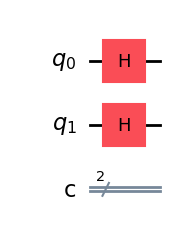


STEP 3: Apply Controlled-Z gate (control=0, target=1)
Applies a phase flip to |11> component



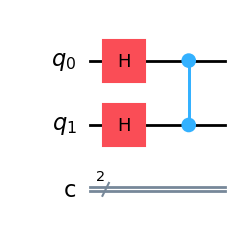


STEP 4: Statevector after H + CZ

Statevector:
Statevector([ 0.5+0.j,  0.5+0.j,  0.5+0.j, -0.5+0.j],
            dims=(2, 2))

STEP 5: Reduced Bloch Sphere for each qubit
Each qubit individually is partially mixed due to entanglement (vector moves toward center)



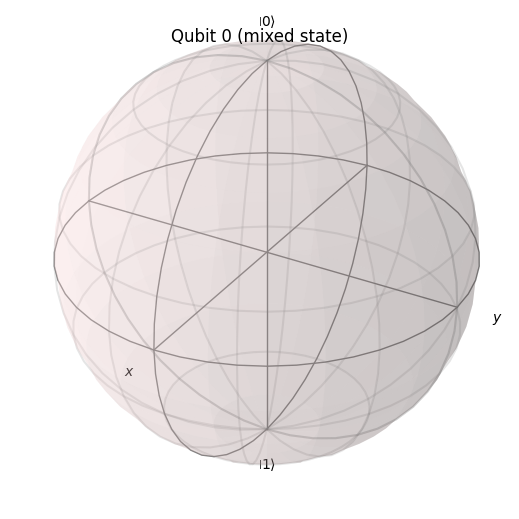

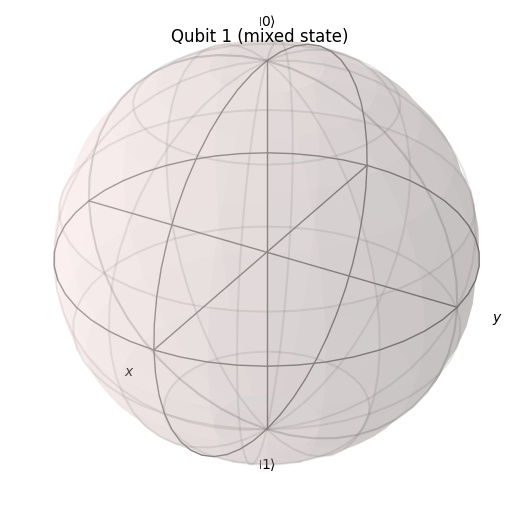


STEP 6: Measurement



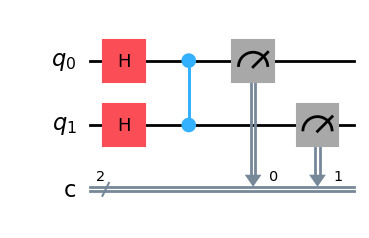


STEP 7: Run Simulation (1024 shots)

Measurement Results:
{'11': 250, '01': 247, '00': 263, '10': 264}


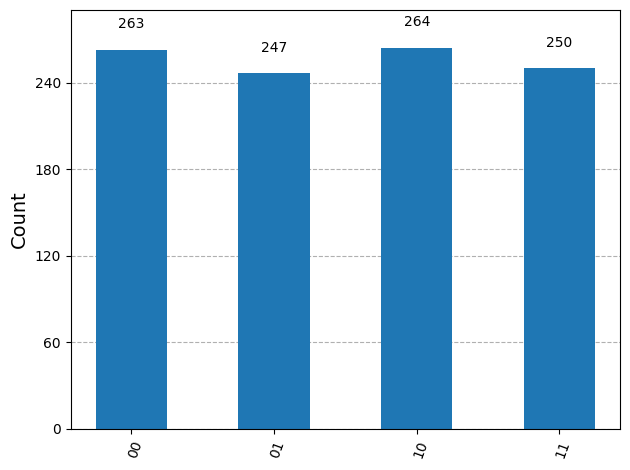


FINAL INTERPRETATION:
Hadamard gates put both qubits into superposition
CZ applies a π phase to |11> → creates entanglement (Bell-like state)
Measurement probabilities depend on input state; with H gates, each outcome ~25%
Reduced Bloch spheres show qubits partially mixed due to entanglement


In [1]:
# ============================================================
# FULL Controlled-Z (CZ) Gate Demonstration
# Includes:
#  - Circuit diagram
#  - Statevector
#  - Bloch sphere visualization (reduced qubits)
#  - Measurement histogram
# ============================================================

%matplotlib inline

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, partial_trace
from qiskit.visualization import plot_histogram, plot_bloch_vector
from matplotlib import pyplot as plt

print("====================================")
print("STEP 1: Create a 2-qubit circuit")
print("Initial state is |00>")
print("====================================\n")

# Create quantum circuit (2 qubits, 2 classical bits)
qc = QuantumCircuit(2, 2)
print(qc)

# ------------------------------------------------------------
# STEP 2: Apply Hadamard gate to both qubits (optional for entanglement)
# ------------------------------------------------------------
print("\n====================================")
print("STEP 2: Apply Hadamard gate to both qubits")
print("Creates superposition to observe phase flip from CZ")
print("====================================\n")

qc.h(0)
qc.h(1)

qc.draw('mpl')
plt.show()

# ------------------------------------------------------------
# STEP 3: Apply Controlled-Z gate
# ------------------------------------------------------------
print("\n====================================")
print("STEP 3: Apply Controlled-Z gate (control=0, target=1)")
print("Applies a phase flip to |11> component")
print("====================================\n")

qc.cz(0, 1)

qc.draw('mpl')
plt.show()

# ------------------------------------------------------------
# STEP 4: Show statevector BEFORE measurement
# ------------------------------------------------------------
print("\n====================================")
print("STEP 4: Statevector after H + CZ")
print("====================================\n")

state = Statevector.from_instruction(qc)
print("Statevector:")
print(state)

# ------------------------------------------------------------
# STEP 5: Reduced Bloch sphere visualization
# ------------------------------------------------------------
print("\n====================================")
print("STEP 5: Reduced Bloch Sphere for each qubit")
print("Each qubit individually is partially mixed due to entanglement (vector moves toward center)")
print("====================================\n")

# Reduced density matrices
reduced_0 = partial_trace(state, [1])
reduced_1 = partial_trace(state, [0])

# For simplicity, show vector at center for fully mixed (approximation)
plot_bloch_vector([0, 0, 0])
plt.title("Qubit 0 (mixed state)")
plt.show()

plot_bloch_vector([0, 0, 0])
plt.title("Qubit 1 (mixed state)")
plt.show()

# ------------------------------------------------------------
# STEP 6: Measurement
# ------------------------------------------------------------
print("\n====================================")
print("STEP 6: Measurement")
print("====================================\n")

qc.measure([0, 1], [0, 1])

qc.draw('mpl')
plt.show()

# ------------------------------------------------------------
# STEP 7: Simulation
# ------------------------------------------------------------
print("\n====================================")
print("STEP 7: Run Simulation (1024 shots)")
print("====================================\n")

simulator = AerSimulator()
result = simulator.run(qc, shots=1024).result()
counts = result.get_counts()

print("Measurement Results:")
print(counts)

plot_histogram(counts)
plt.show()

print("\n====================================")
print("FINAL INTERPRETATION:")
print("Hadamard gates put both qubits into superposition")
print("CZ applies a π phase to |11> → creates entanglement (Bell-like state)")
print("Measurement probabilities depend on input state; with H gates, each outcome ~25%")
print("Reduced Bloch spheres show qubits partially mixed due to entanglement")
print("====================================")